# Telephone Game — Example Chains

Iterated image↔text relay: **word → image → caption → image → caption → …** (5 iters). Each panel shows iteration *t*'s **image** with the **caption** read from it underneath — and that caption is the prompt that generated the *next* image, so left→right is the literal image-text-image-text telephone. Images below are pre-rendered (Gemini/Grok emit JPEG with a `.png` ext, so the loader uses PIL). Re-run the cells to regenerate from `data/telephone/`.

In [ ]:
import textwrap
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("data/telephone"); N_ITERS = 5

def _readable(p):
    try: Image.open(p).load(); return True
    except Exception: return False

def _first_complete(family, word, n=N_ITERS):
    base = ROOT/family/word
    for ci in range(30):
        d = base/f"c{ci:02d}"
        if d.exists() and all((d/f"i{t}.txt").exists() and _readable(d/f"i{t}.png") for t in range(n)):
            return ci
    return None

def show_chain(family, word, chain=None, n=N_ITERS):
    if chain is None:
        chain = _first_complete(family, word)
        if chain is None: print(f"no readable chain for {family}/{word}"); return
    d = ROOT/family/word/f"c{chain:02d}"
    fig, axes = plt.subplots(1, n, figsize=(3.6*n, 5.0))
    for t in range(n):
        ax = axes[t]; p = d/f"i{t}.png"
        try: ax.imshow(np.asarray(Image.open(p).convert("RGB")))  # PIL: JPEG-as-.png ok
        except Exception: ax.text(.5,.5,"[unreadable]",ha="center",va="center",transform=ax.transAxes,color="crimson")
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        ax.set_title(f"iter {t} · image", fontsize=10)
        cap = (d/f"i{t}.txt").read_text().strip() if (d/f"i{t}.txt").exists() else ""
        ax.set_xlabel(textwrap.fill(f'"{cap}"', 42), fontsize=8)
    fig.suptitle(f"{family} · {word} · chain c{chain:02d}    (word → image → caption → image → …)", fontsize=13, y=1.03)
    plt.tight_layout(); plt.show()

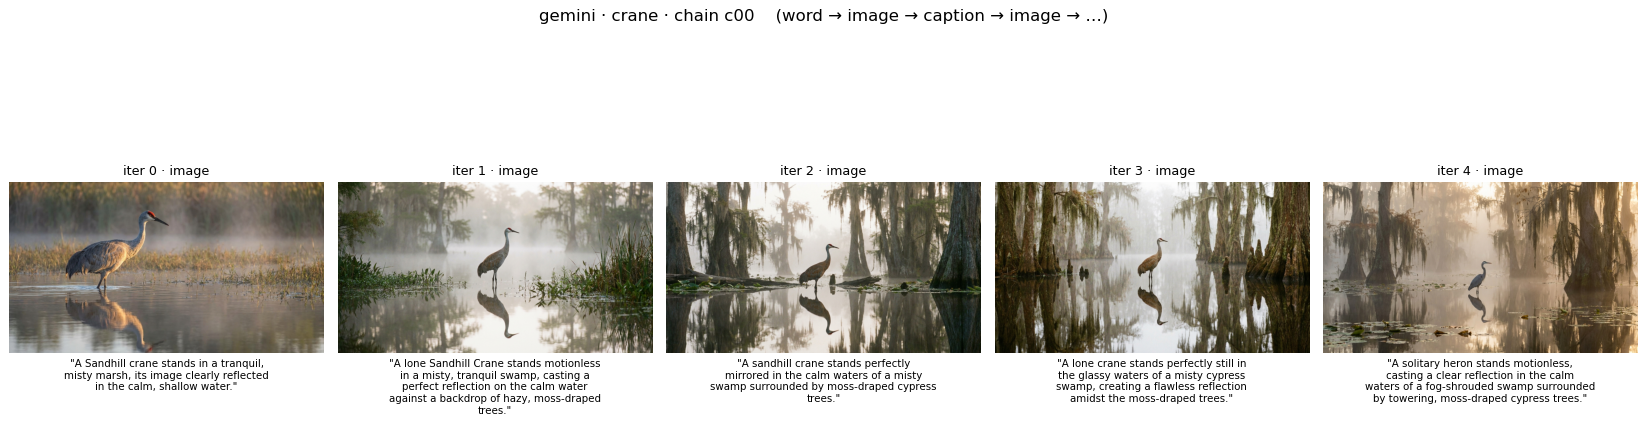

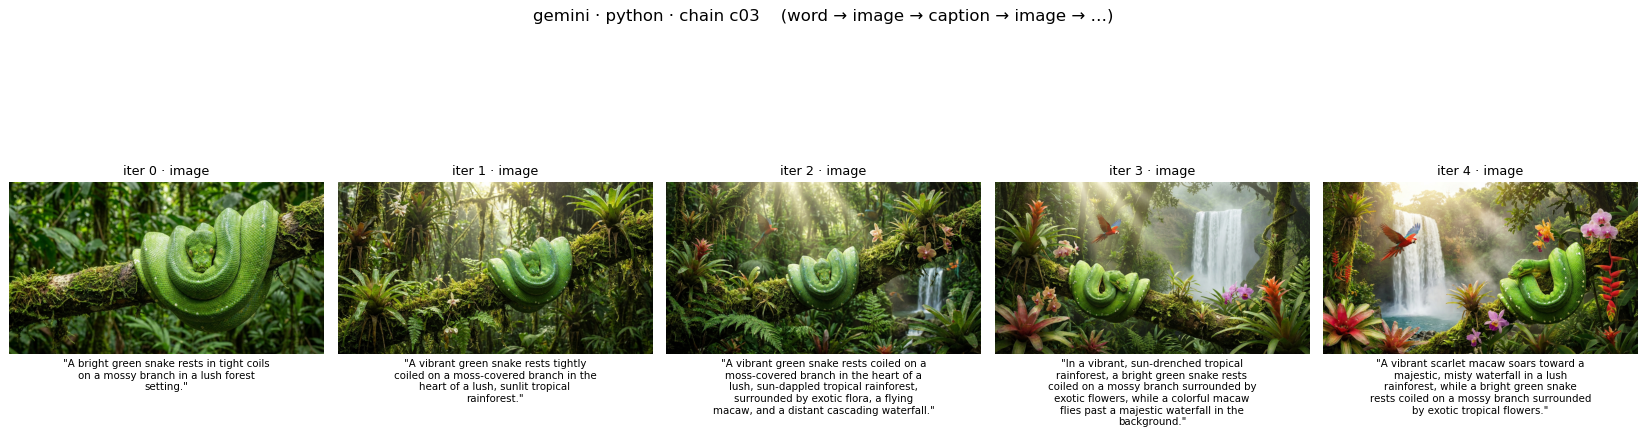

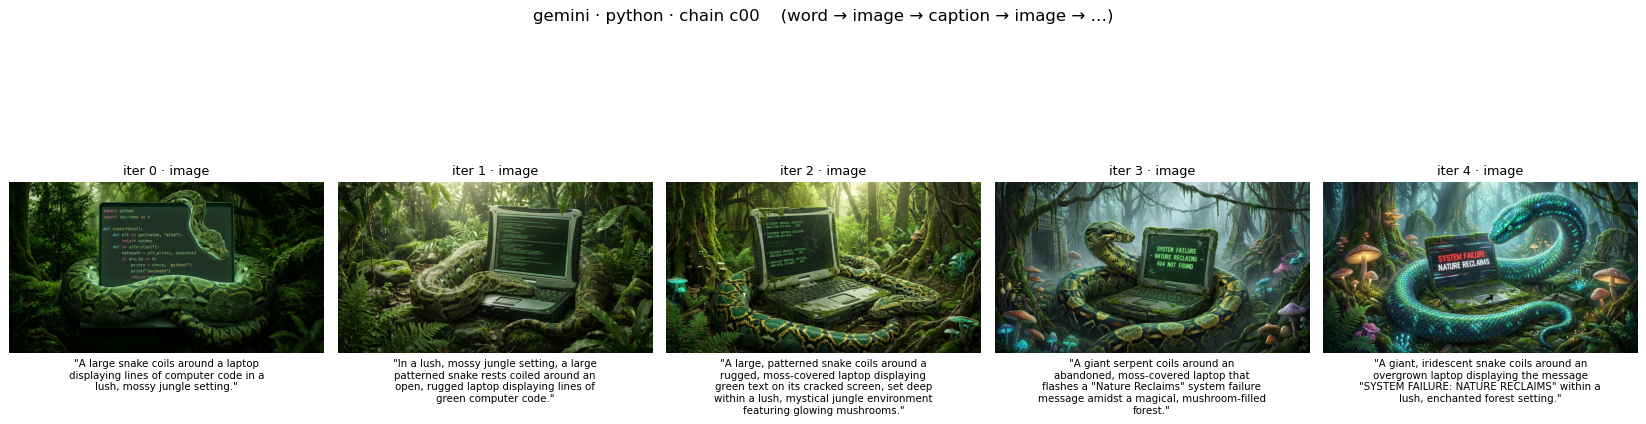

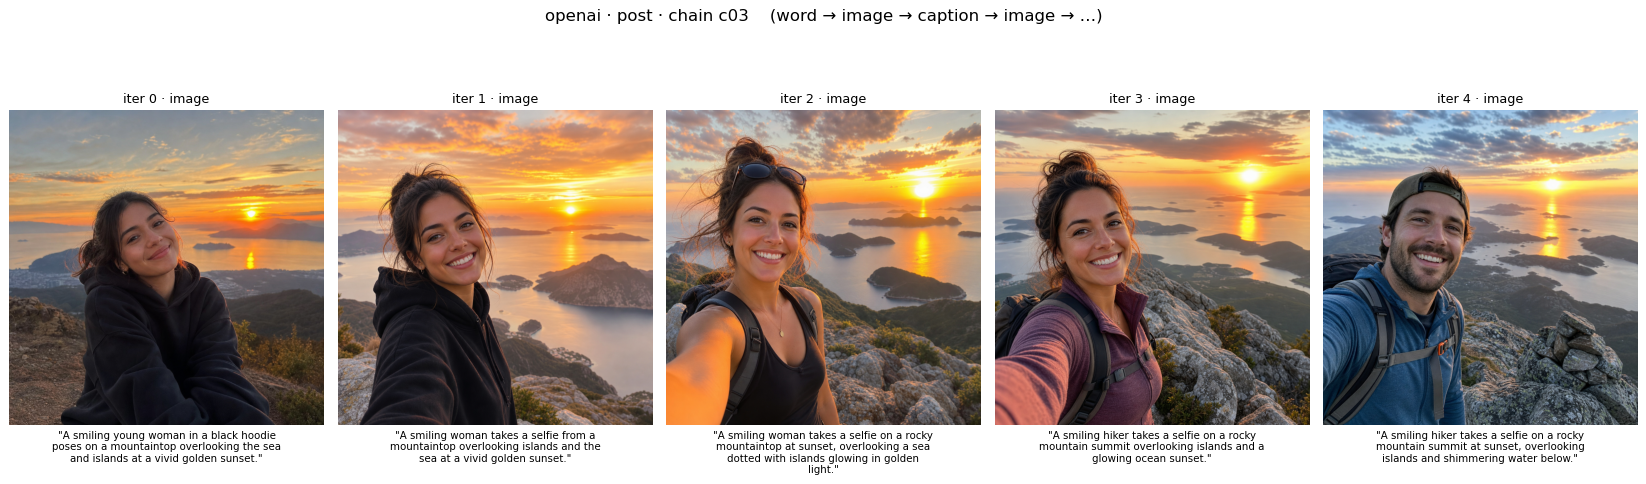

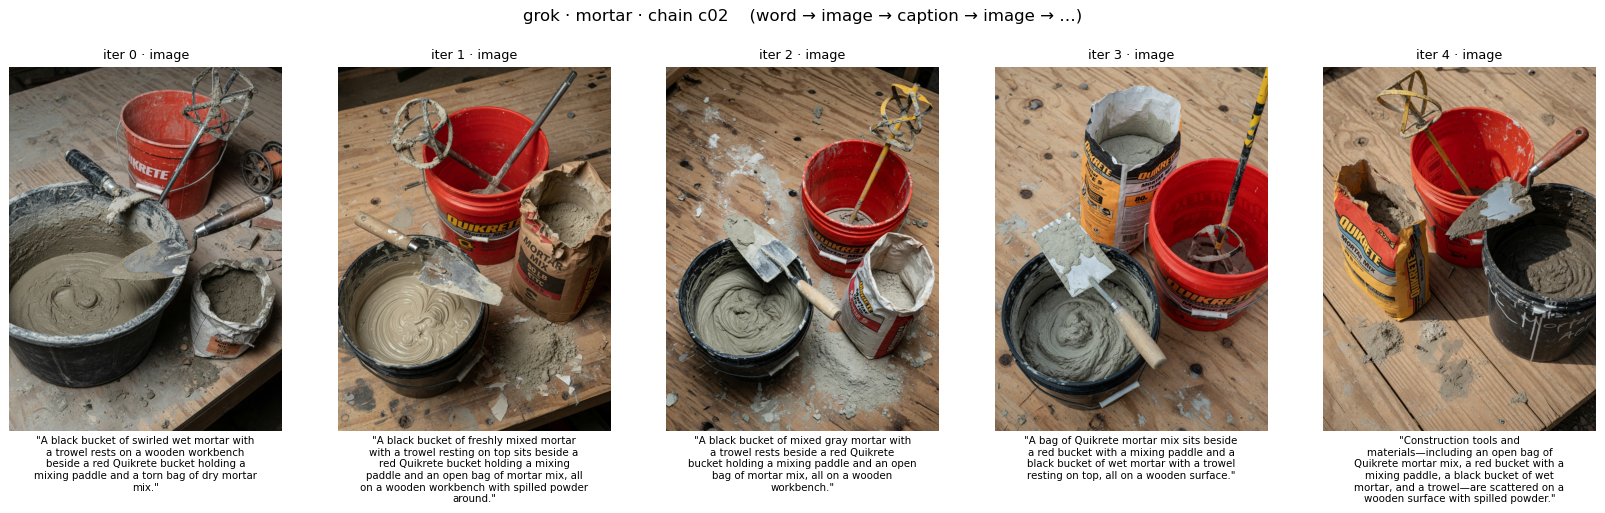

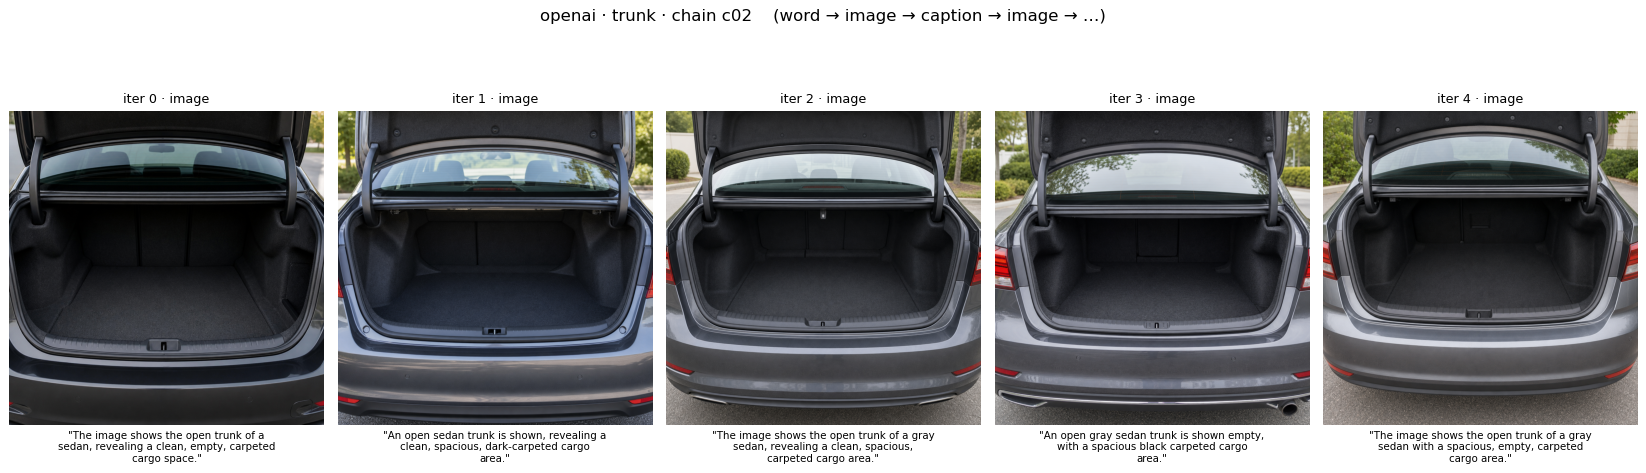

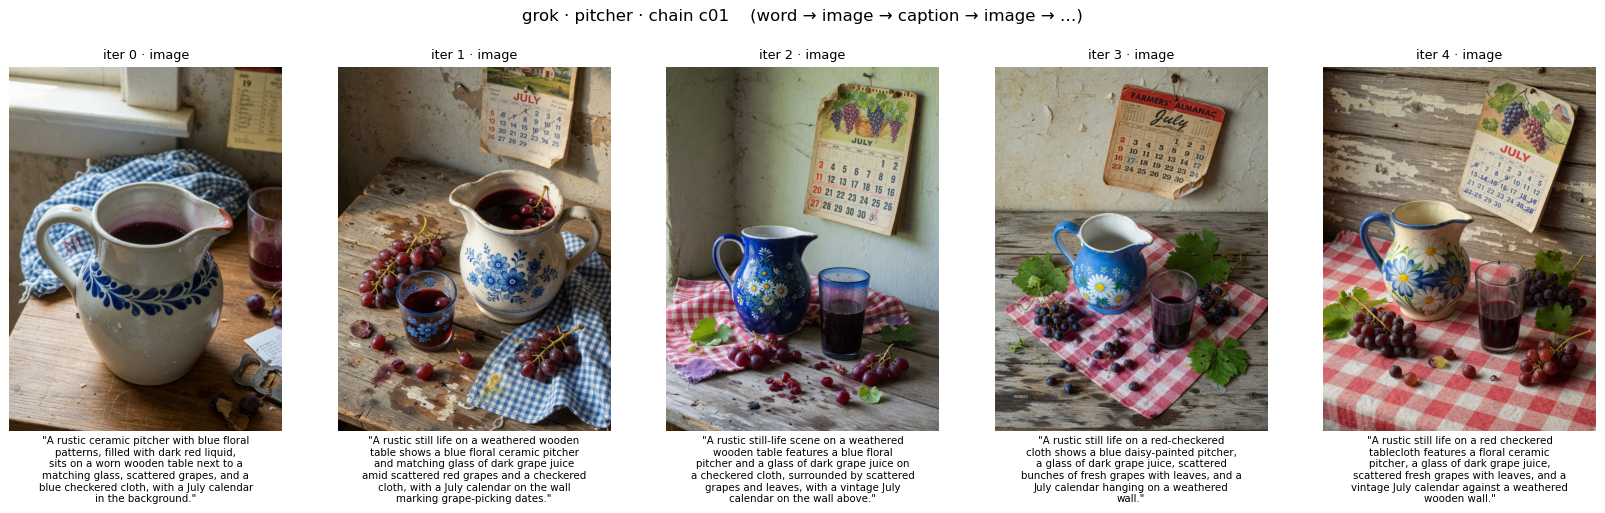

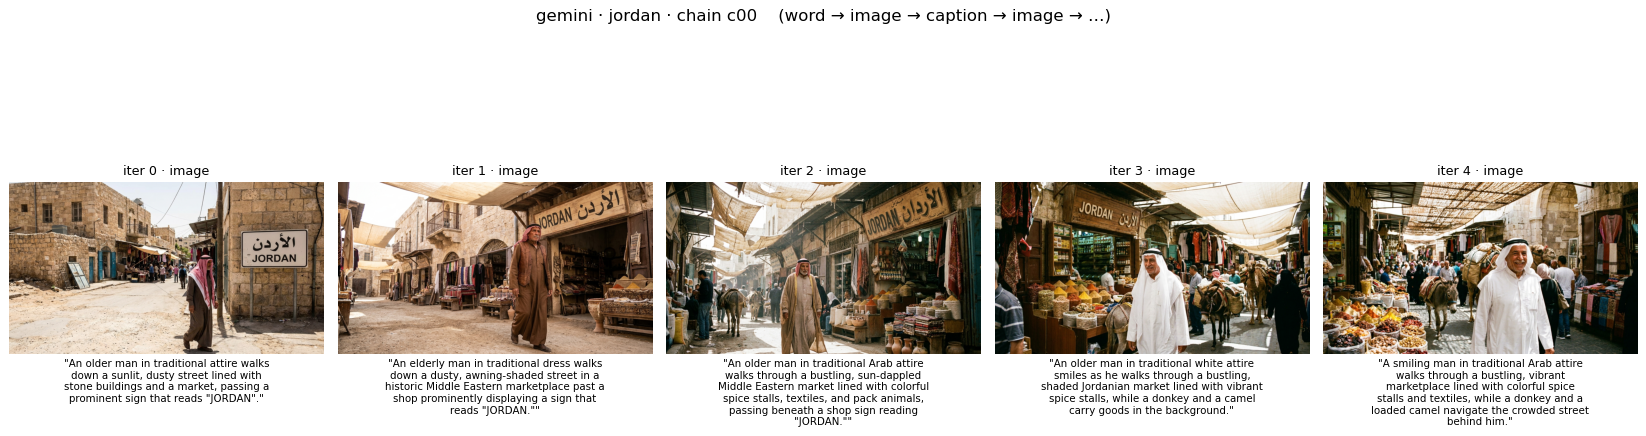

In [1]:
EXAMPLES = [
    ("gemini","crane",0), ("gemini","python",3), ("gemini","python",0),
    ("openai","post"), ("grok","mortar"), ("openai","trunk"),
    ("grok","pitcher"), ("gemini","jordan"),
]
for ex in EXAMPLES:
    show_chain(ex[0], ex[1], ex[2] if len(ex) > 2 else None)